# EN3160 Assignment 3: Neural Networks, CNNs, and Transfer Learning
* **Student Name:** Chandrakumara H.A.D.C.
* **Index Number:** 230100M
* **GitHub Repository:** [https://github.com/dulaksha-chathura/A03-on-CNNs](https://github.com/dulaksha-chathura/A03-on-CNNs)

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Question 1: Manual Two-Layer Dense Network on CIFAR-10
In this section, we extend Listing 1 from the assignment by:
1. Adding a hidden middle layer with **100 nodes** and a **sigmoid activation function**.
2. Replacing MSE loss with **Cross-Entropy loss** (with manual softmax/cross-entropy computation or utilizing stable formulations).
3. Training the network for **10 epochs** and reporting training and test accuracies.

Epoch 1/10, Loss: 1.9870
Epoch 2/10, Loss: 1.7902
Epoch 3/10, Loss: 1.7236
Epoch 4/10, Loss: 1.6835
Epoch 5/10, Loss: 1.6536
Epoch 6/10, Loss: 1.6296
Epoch 7/10, Loss: 1.6094
Epoch 8/10, Loss: 1.5919
Epoch 9/10, Loss: 1.5763
Epoch 10/10, Loss: 1.5628


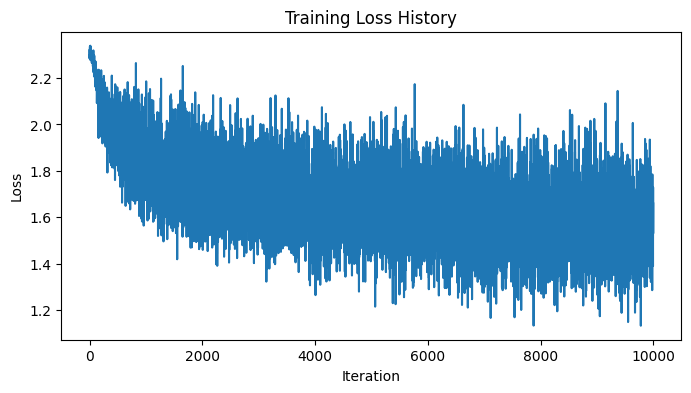

Training Accuracy: 46.51%
Test Accuracy: 44.52%


In [5]:

# 1. Data Loading for CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters and Hyperparameters
Din = 3 * 32 * 32  # Input size
H = 100            # Hidden layer size
K = 10             # Output size (classes)

# Initialize weights and biases using normal distribution scaled properly
std = 1e-2
w1 = torch.randn(Din, H, requires_grad=False) * std
b1 = torch.zeros(H, requires_grad=False)

w2 = torch.randn(H, K, requires_grad=False) * std
b2 = torch.zeros(K, requires_grad=False)

epochs = 10
lr = 0.05
lr_decay = 0.9
loss_history = []

def sigmoid(x):
    return 1.0 / (1.0 + torch.exp(-x))

def softmax(x):
    exp_x = torch.exp(x - torch.max(x, dim=1, keepdim=True).values)
    return exp_x / torch.sum(exp_x, dim=1, keepdim=True)

# 3. Training Loop with Manual Forward and Backward Pass
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, Din)
        
        # Forward Pass
        z1 = x_train.mm(w1) + b1
        h1 = sigmoid(z1)
        z2 = h1.mm(w2) + b2
        scores = z2
        
        # Softmax and Cross-Entropy Loss
        probs = softmax(scores)
        correct_log_probs = -torch.log(probs[range(Ntr), labels] + 1e-8)
        loss = torch.sum(correct_log_probs) / Ntr
        
        loss_history.append(loss.item())
        running_loss += loss.item()
        
        # Backpropagation
        # Gradient of loss w.r.t. scores (softmax + cross entropy gradient)
        dscores = probs
        dscores[range(Ntr), labels] -= 1
        dscores /= Ntr
        
        # Backprop through layer 2
        dw2 = h1.t().mm(dscores)
        db2 = dscores.sum(dim=0)
        
        # Backprop through hidden layer
        dh1 = dscores.mm(w2.t())
        dz1 = dh1 * h1 * (1.0 - h1)  # Sigmoid derivative
        
        dw1 = x_train.t().mm(dz1)
        db1 = dz1.sum(dim=0)
        
        # Parameter Update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2
        
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")
    lr *= lr_decay

# 4. Plot Loss History
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Training Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Training Accuracy
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, Din)
        h1 = sigmoid(x_train.mm(w1) + b1)
        outputs = h1.mm(w2) + b2
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training Accuracy: {train_acc:.2f}%")

# 6. Test Accuracy
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, Din)
        h1 = sigmoid(x_test.mm(w1) + b1)
        outputs = h1.mm(w2) + b2
        _, predicted = torch.max(outputs, 1)
        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test Accuracy: {test_acc:.2f}%")

# Part 2: Convolutional Neural Networks on MNIST
In this section, we implement two models:
1. **LeNet-5 Network**[cite: 1]
2. **Modern Small CNN** (featuring 3 convolutional layers, batch normalization, and dropout)[cite: 1]
Both are trained for 10 epochs, evaluated, and compared via loss/accuracy curves and confusion matrices[cite: 1].

100%|██████████| 9.91M/9.91M [00:07<00:00, 1.31MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 110kB/s]
100%|██████████| 1.65M/1.65M [00:07<00:00, 217kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 304kB/s]


Training LeNet-5...
[LeNet-5] Epoch 1/10 | Test Acc: 96.93%
[LeNet-5] Epoch 2/10 | Test Acc: 97.78%
[LeNet-5] Epoch 3/10 | Test Acc: 98.27%
[LeNet-5] Epoch 4/10 | Test Acc: 98.25%
[LeNet-5] Epoch 5/10 | Test Acc: 98.60%
[LeNet-5] Epoch 6/10 | Test Acc: 98.40%
[LeNet-5] Epoch 7/10 | Test Acc: 98.59%
[LeNet-5] Epoch 8/10 | Test Acc: 98.34%
[LeNet-5] Epoch 9/10 | Test Acc: 98.56%
[LeNet-5] Epoch 10/10 | Test Acc: 98.59%

Training Modern Small CNN...
[Modern CNN] Epoch 1/10 | Test Acc: 96.04%
[Modern CNN] Epoch 2/10 | Test Acc: 96.57%
[Modern CNN] Epoch 3/10 | Test Acc: 96.74%
[Modern CNN] Epoch 4/10 | Test Acc: 97.26%
[Modern CNN] Epoch 5/10 | Test Acc: 96.05%
[Modern CNN] Epoch 6/10 | Test Acc: 98.55%
[Modern CNN] Epoch 7/10 | Test Acc: 98.67%
[Modern CNN] Epoch 8/10 | Test Acc: 98.85%
[Modern CNN] Epoch 9/10 | Test Acc: 98.84%
[Modern CNN] Epoch 10/10 | Test Acc: 98.67%


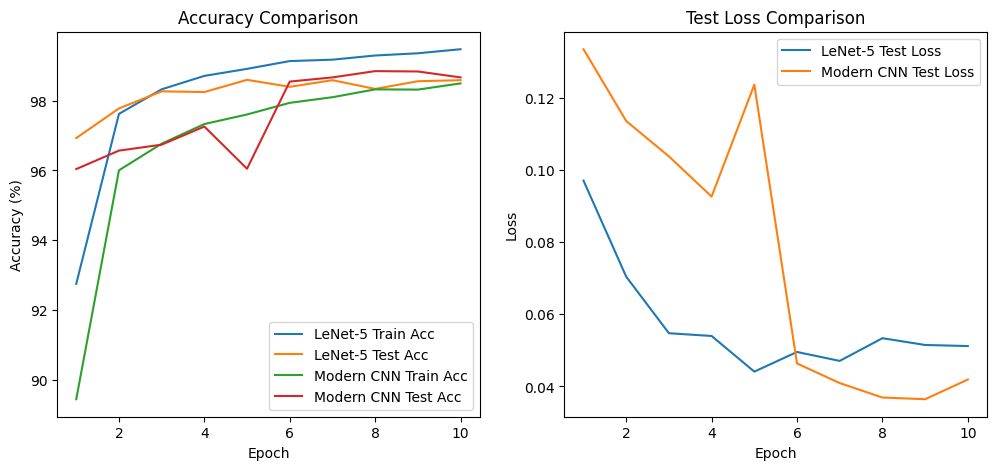

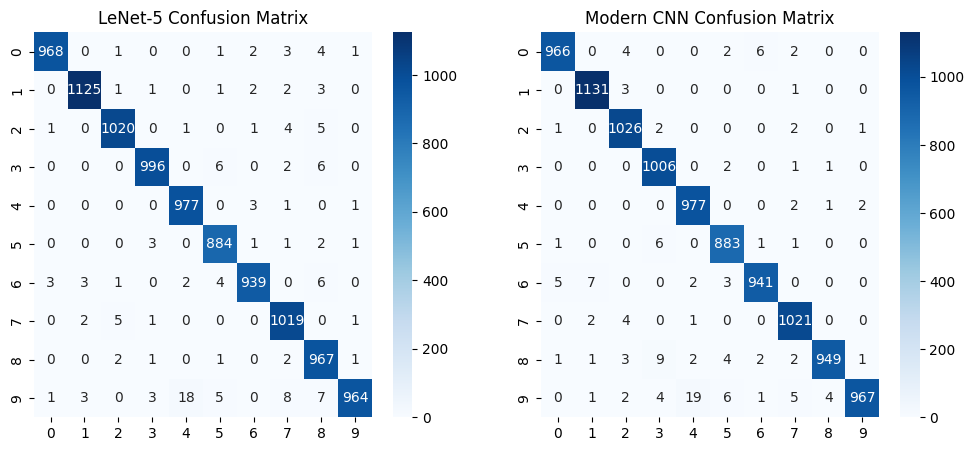

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Data loading for MNIST
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

# 1. LeNet-5 Architecture
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=2),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5, stride=1),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# 2. Modern Small CNN Architecture (with BatchNorm and Dropout)
class ModernSmallCNN(nn.Module):
    def __init__(self):
        super(ModernSmallCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# Training & Evaluation Function
def train_and_evaluate(model, model_name, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct, total = 0, 0
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
        train_losses.append(running_loss / len(trainloader))
        train_accs.append(100. * correct / total)
        
        # Evaluation
        model.eval()
        test_loss = 0.0
        correct, total = 0, 0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for inputs, labels in testloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                test_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
                
                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                
        test_losses.append(test_loss / len(testloader))
        test_accs.append(100. * correct / total)
        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | Test Acc: {test_accs[-1]:.2f}%")
        
    return train_losses, test_losses, train_accs, test_accs, np.array(all_preds), np.array(all_labels)

# Train LeNet-5
print("Training LeNet-5...")
lenet_results = train_and_evaluate(LeNet5(), "LeNet-5")

# Train Modern CNN
print("\nTraining Modern Small CNN...")
modern_results = train_and_evaluate(ModernSmallCNN(), "Modern CNN")

# Plotting Metrics
epochs_range = range(1, 11)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, lenet_results[2], label='LeNet-5 Train Acc')
plt.plot(epochs_range, lenet_results[3], label='LeNet-5 Test Acc')
plt.plot(epochs_range, modern_results[2], label='Modern CNN Train Acc')
plt.plot(epochs_range, modern_results[3], label='Modern CNN Test Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Accuracy Comparison')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, lenet_results[1], label='LeNet-5 Test Loss')
plt.plot(epochs_range, modern_results[1], label='Modern CNN Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Test Loss Comparison')
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(confusion_matrix(lenet_results[5], lenet_results[4]), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('LeNet-5 Confusion Matrix')
sns.heatmap(confusion_matrix(modern_results[5], modern_results[4]), annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Modern CNN Confusion Matrix')
plt.show()

# Part 3: Transfer Learning using ResNet18 (Hymenoptera Dataset)
In this section, we utilize a pre-trained ResNet18 network trained on ImageNet-1K[cite: 1] to classify the hymenoptera dataset (ants and bees) using:
1. **Fine-Tuning** (updating all network weights)[cite: 1].
2. **Feature Extraction** (freezing backbone weights and training only the classifier)[cite: 1].

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
import os

# Data augmentations and normalization for training
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Assuming hymenoptera_data folder is available or downloaded
# e.g., download from PyTorch tutorials dataset source
import urllib.request
import zipfile

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
urllib.request.urlretrieve(url, "hymenoptera_data.zip")
with zipfile.ZipFile("hymenoptera_data.zip", 'r') as zip_ref:
    zip_ref.extractall(".")

data_dir = './hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=32, shuffle=True, num_workers=2) for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, criterion, optimizer, num_epochs=5):
    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

    return model

print("--- 1. Fine-Tuning ResNet18 ---")
model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
model_ft = train_model(model_ft, criterion, optimizer_ft, num_epochs=5)

print("\n--- 2. Feature Extraction (Frozen Backbone) ---")
model_conv = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
model_conv = train_model(model_conv, criterion, optimizer_conv, num_epochs=5)

--- 1. Fine-Tuning ResNet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\MSI/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:11<00:00, 3.95MB/s]


Epoch 1/5
----------
train Loss: 0.6906 Acc: 0.5205
val Loss: 0.5461 Acc: 0.7124
Epoch 2/5
----------
train Loss: 0.4589 Acc: 0.8156
val Loss: 0.3206 Acc: 0.9085
Epoch 3/5
----------
train Loss: 0.3226 Acc: 0.8811
val Loss: 0.2405 Acc: 0.9346
Epoch 4/5
----------
train Loss: 0.2282 Acc: 0.9344
val Loss: 0.2095 Acc: 0.9412
Epoch 5/5
----------
train Loss: 0.1837 Acc: 0.9426
val Loss: 0.1957 Acc: 0.9412

--- 2. Feature Extraction (Frozen Backbone) ---
Epoch 1/5
----------
train Loss: 0.7234 Acc: 0.5328
val Loss: 0.6701 Acc: 0.5882
Epoch 2/5
----------
train Loss: 0.5833 Acc: 0.6598
val Loss: 0.4208 Acc: 0.8889
Epoch 3/5
----------
train Loss: 0.4139 Acc: 0.8361
val Loss: 0.3178 Acc: 0.9281
Epoch 4/5
----------
train Loss: 0.3299 Acc: 0.8852
val Loss: 0.2629 Acc: 0.9477
Epoch 5/5
----------
train Loss: 0.2747 Acc: 0.9262
val Loss: 0.2457 Acc: 0.9412
